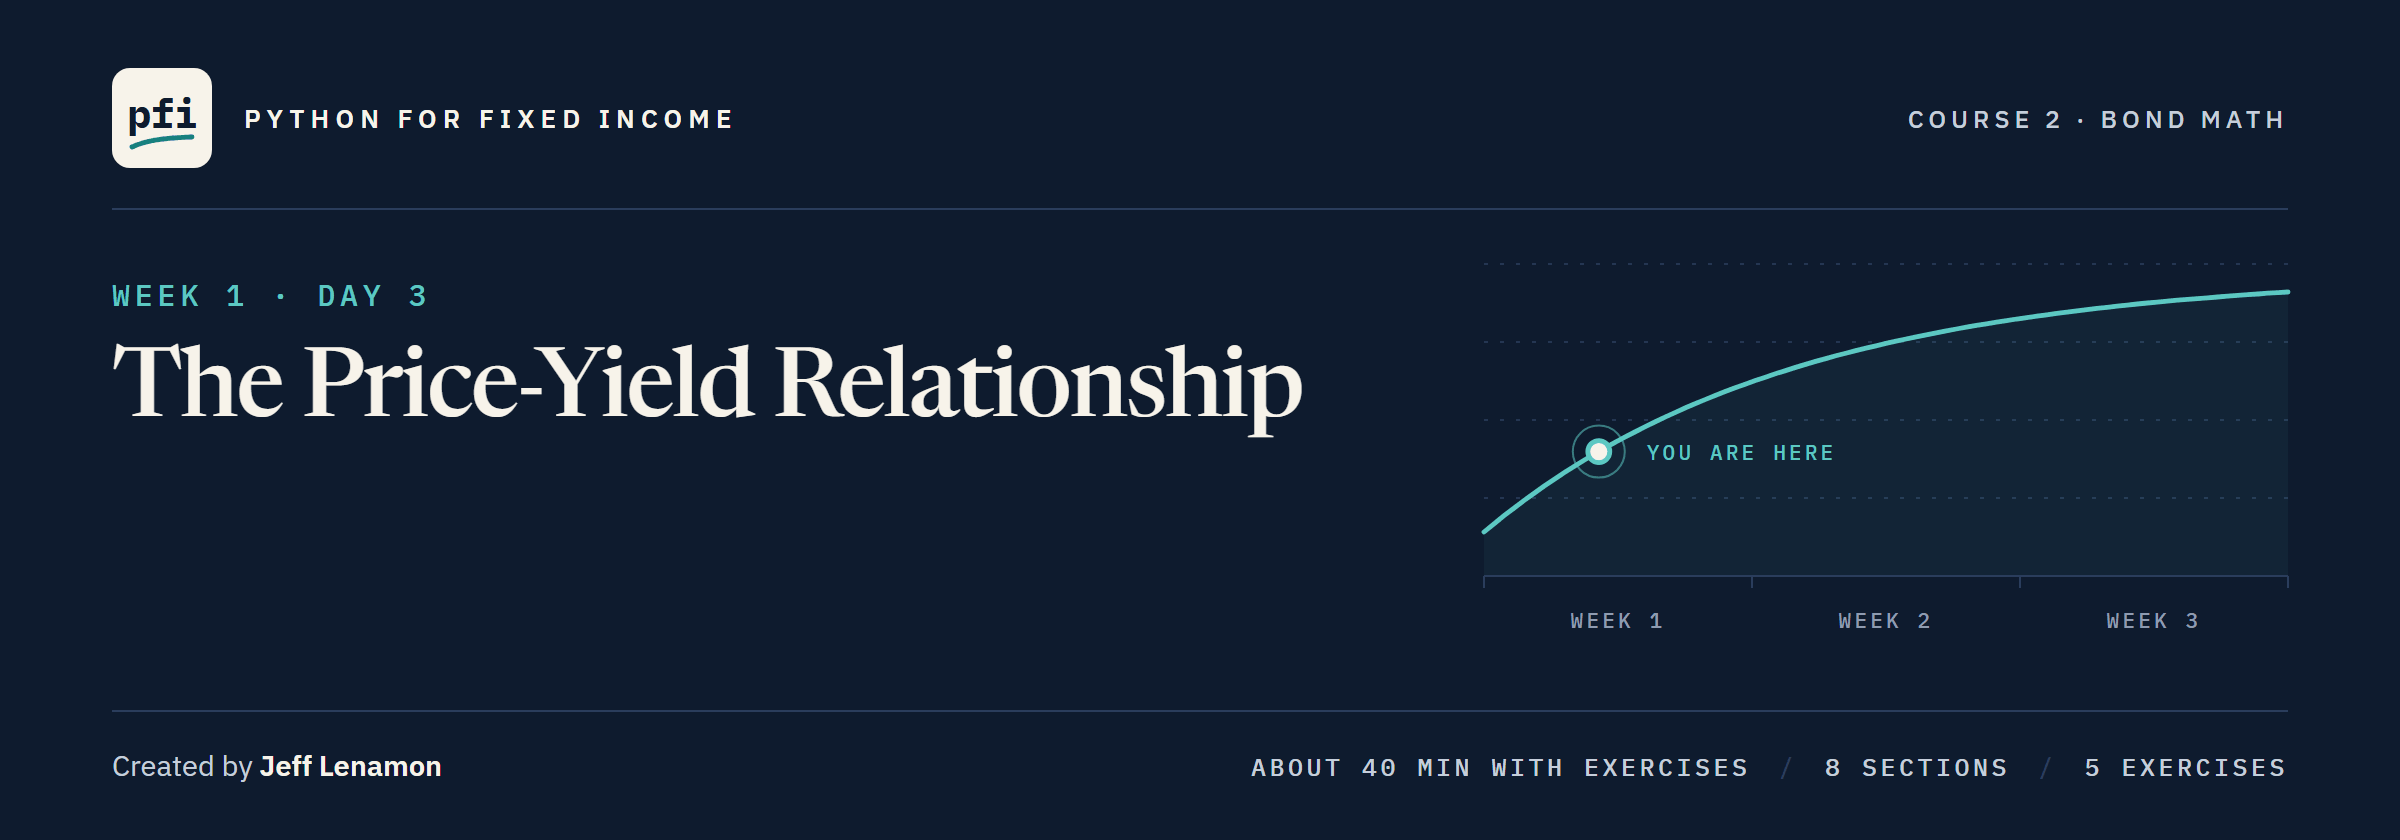

# The Price-Yield Relationship

Week 1, Day 3. Why a bond prices above, at, or below 100, how its price moves with its yield and with time, and a yield restated at another frequency, in a new function tested against Excel's EFFECT and NOMINAL.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day3/03_the_price_yield_relationship.ipynb)

### The Desk Lead's Note

> Notebook 02 priced the four: Pellwick above 100, Dunmarrow on it, Quorvane and Halvering below. Tell me why each sits where it does. Show me how each price moves as yields move, and which bond moves most. If yields never move, where does each price go? A dealer offers an annual-pay bond at 5.45 against Quorvane's 5.40: which yields more? Put the restatement in `bondmath`, docstring first, prove it against Excel's EFFECT and NOMINAL, commit with a message that says why, and take it home.

The issuers are invented; every yield move is a what-if.

**Four prices, four places against 100: today says why.**

### Start the Day

As in notebook 02, the setup makes a new work folder holding the module, its tests, and the first two commits.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 02 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(3)

Work folder pfi_course2_03_k4w7q2xr: 2 data files, the module as notebook 02 left it, 2 commits


### Imports and the House Colours

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import bondmath

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### The Module So Far

In [3]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......                                                                   [100%]
6 passed in 0.50s



### Four Bonds, Notebook 02's Prices

In [4]:
bonds = pd.DataFrame({
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'years': [5, 7, 3, 10],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
})
bonds['price'] = [bondmath.price_from_yield(c, y, t)
                  for c, y, t in zip(bonds['coupon_pct'], bonds['yield_pct'], bonds['years'])]
bonds.round(4)

,issuer,ticker,coupon_pct,years,yield_pct,price
0,Quorvane Energy,QVNE,5.250,5,5.400,99.3503
1,Dunmarrow Rail,DNMR,6.125,7,6.125,100.0000
2,Pellwick Paper,PLWK,4.750,3,4.600,100.4159
3,Halvering Foods,HLVF,7.500,10,7.700,98.6227


**Four functions, six tests, four prices: the day starts where notebook 02 ended.**

## Your Route Through Day 3

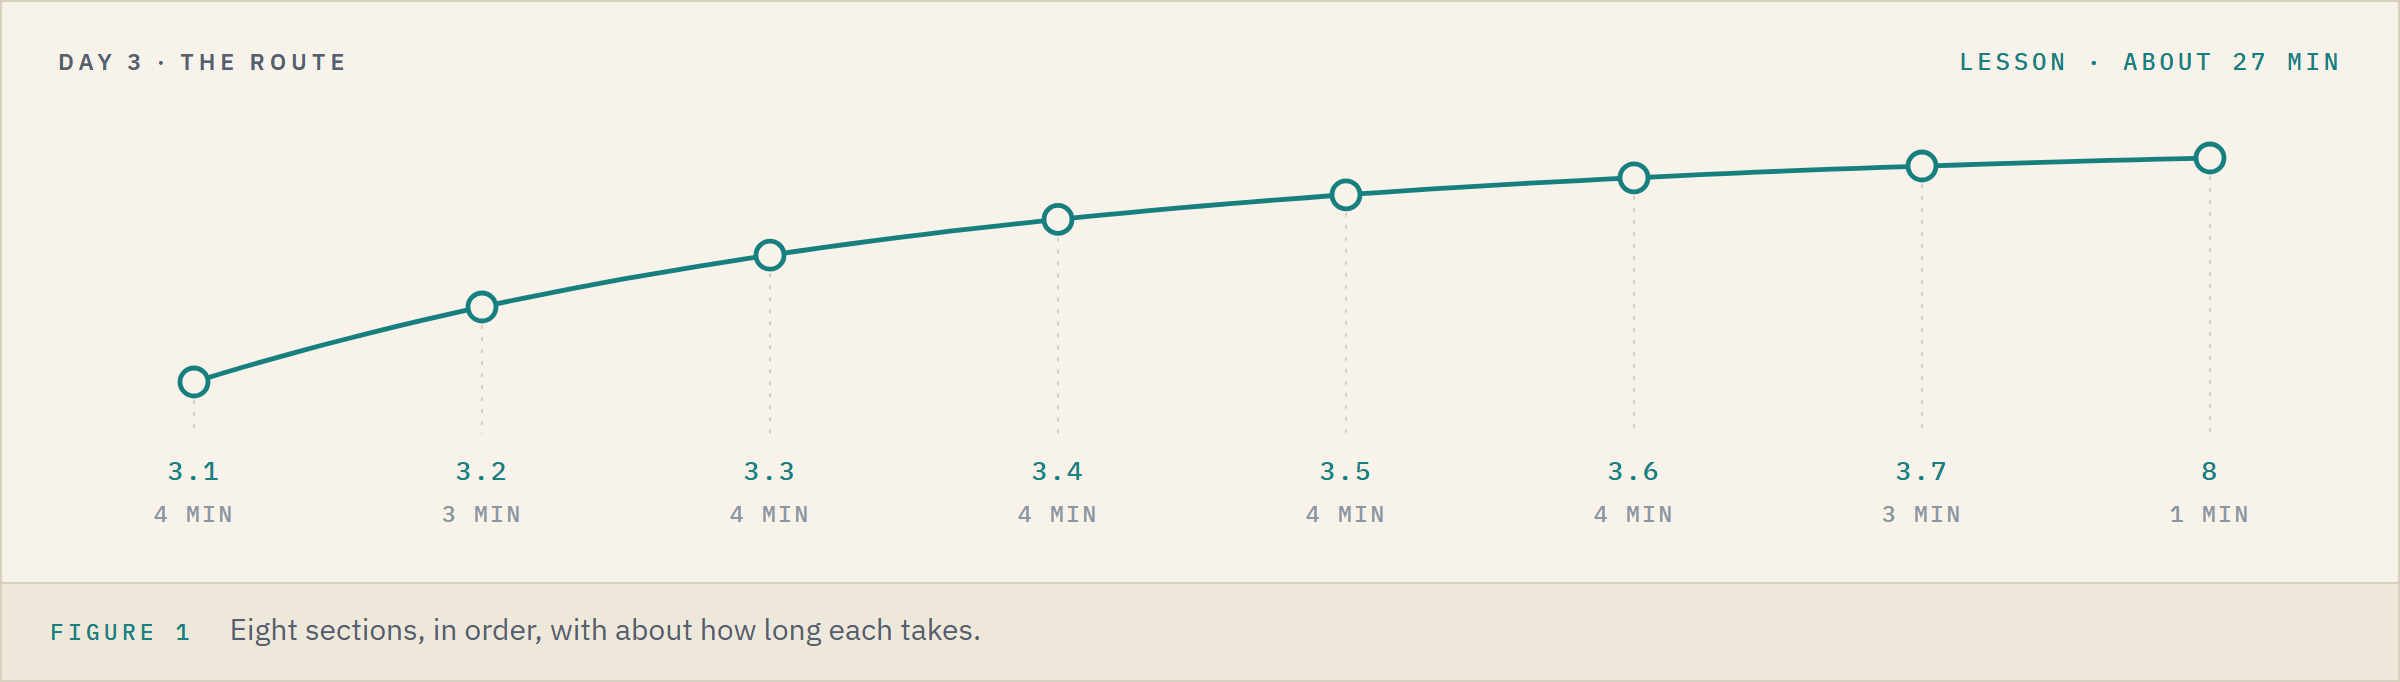

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">3.1</td><td align="left">Par, Premium, and Discount</td><td align="left">4 min</td></tr>
<tr><td align="left">3.2</td><td align="left">The Price-Yield Curve, Charted</td><td align="left">3 min</td></tr>
<tr><td align="left">3.3</td><td align="left">Coupon and Maturity: Which Bond Moves More</td><td align="left">4 min</td></tr>
<tr><td align="left">3.4</td><td align="left">Pull to Par on Coupon Dates</td><td align="left">4 min</td></tr>
<tr><td align="left">3.5</td><td align="left">One Yield, Three Quotes</td><td align="left">4 min</td></tr>
<tr><td align="left">3.6</td><td align="left"><code>convert_yield</code> in Your Module</td><td align="left">4 min</td></tr>
<tr><td align="left">3.7</td><td align="left">A Commit Message That Says Why</td><td align="left">3 min</td></tr>
<tr><td align="left">8</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 27 minutes for the lesson, then about 15 for the five exercises.

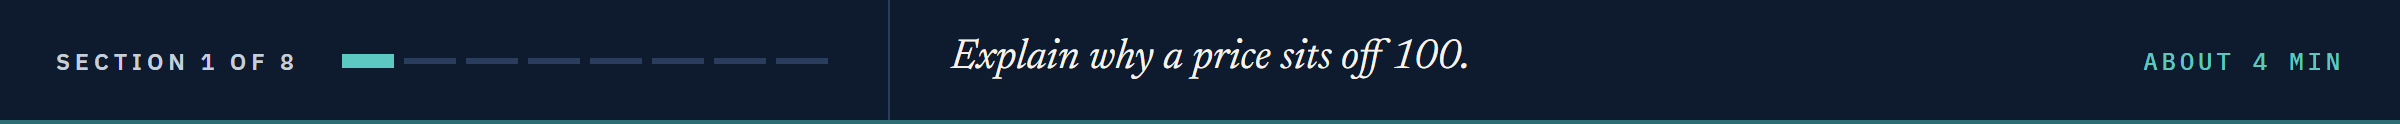

## 3.1 Par, Premium, and Discount

Course 1's Combining and Loading, Part 2 labelled a price premium, par, or discount by looking at the price.
On a coupon date one comparison decides the label before any price is worked: the coupon against the yield.

### Coupon Against Yield

Q. Put each coupon beside its yield, and label each price.

In [5]:
bonds['coupon_minus_yield'] = bonds['coupon_pct'] - bonds['yield_pct']
# round first: Dunmarrow's price is 100.0000000000001, which is 100
rounded = bonds['price'].round(6)
bonds['label'] = np.where(rounded > 100, 'premium', np.where(rounded < 100, 'discount', 'par'))
table = bonds[['ticker', 'coupon_pct', 'yield_pct', 'coupon_minus_yield', 'price', 'label']]
formats = {'coupon_pct': '{:.3f}', 'yield_pct': '{:.3f}', 'coupon_minus_yield': '{:+.3f}',
           'price': '{:.4f}'}
table.style.format(formats).hide(axis='index')

ticker,coupon_pct,yield_pct,coupon_minus_yield,price,label
QVNE,5.250,5.400,-0.150,99.3503,discount
DNMR,6.125,6.125,+0.000,100.0000,par
PLWK,4.750,4.600,+0.150,100.4159,premium
HLVF,7.500,7.700,-0.200,98.6227,discount


In a format, `+` prints the sign of a positive number too: `{:+.3f}` shows `+0.150`.

**Coupon above the yield, premium; equal, par; below, discount.**

### The Extra Coupon, Valued

Pellwick's coupon pays 4.75 / 2 = 2.375 a half-year, where its 4.60 yield asks only 2.300: an extra 0.075, six times.
Notebook 02's `price_from_yield` values any coupon stream; give it the extra, coupon minus yield, as the coupon.
Its price then holds the 100 as well, so take away the 100's share, notebook 01's `present_value`.

Q. What is each bond's extra coupon worth today?

In [6]:
# the coupon's excess over the yield, valued at the yield, without the 100
bonds['extra_pv'] = [bondmath.price_from_yield(c - y, y, t) - bondmath.present_value(100, y, t)
                     for c, y, t in zip(bonds['coupon_pct'], bonds['yield_pct'], bonds['years'])]
# the same number as the price minus 100
assert (bonds['extra_pv'] - (bonds['price'] - 100)).abs().max() < 1e-9
bonds[['ticker', 'coupon_minus_yield', 'extra_pv']].round(6)

,ticker,coupon_minus_yield,extra_pv
0,QVNE,-0.15,-0.649673
1,DNMR,0.00,0.000000
2,PLWK,0.15,0.415887
3,HLVF,-0.20,-1.377264


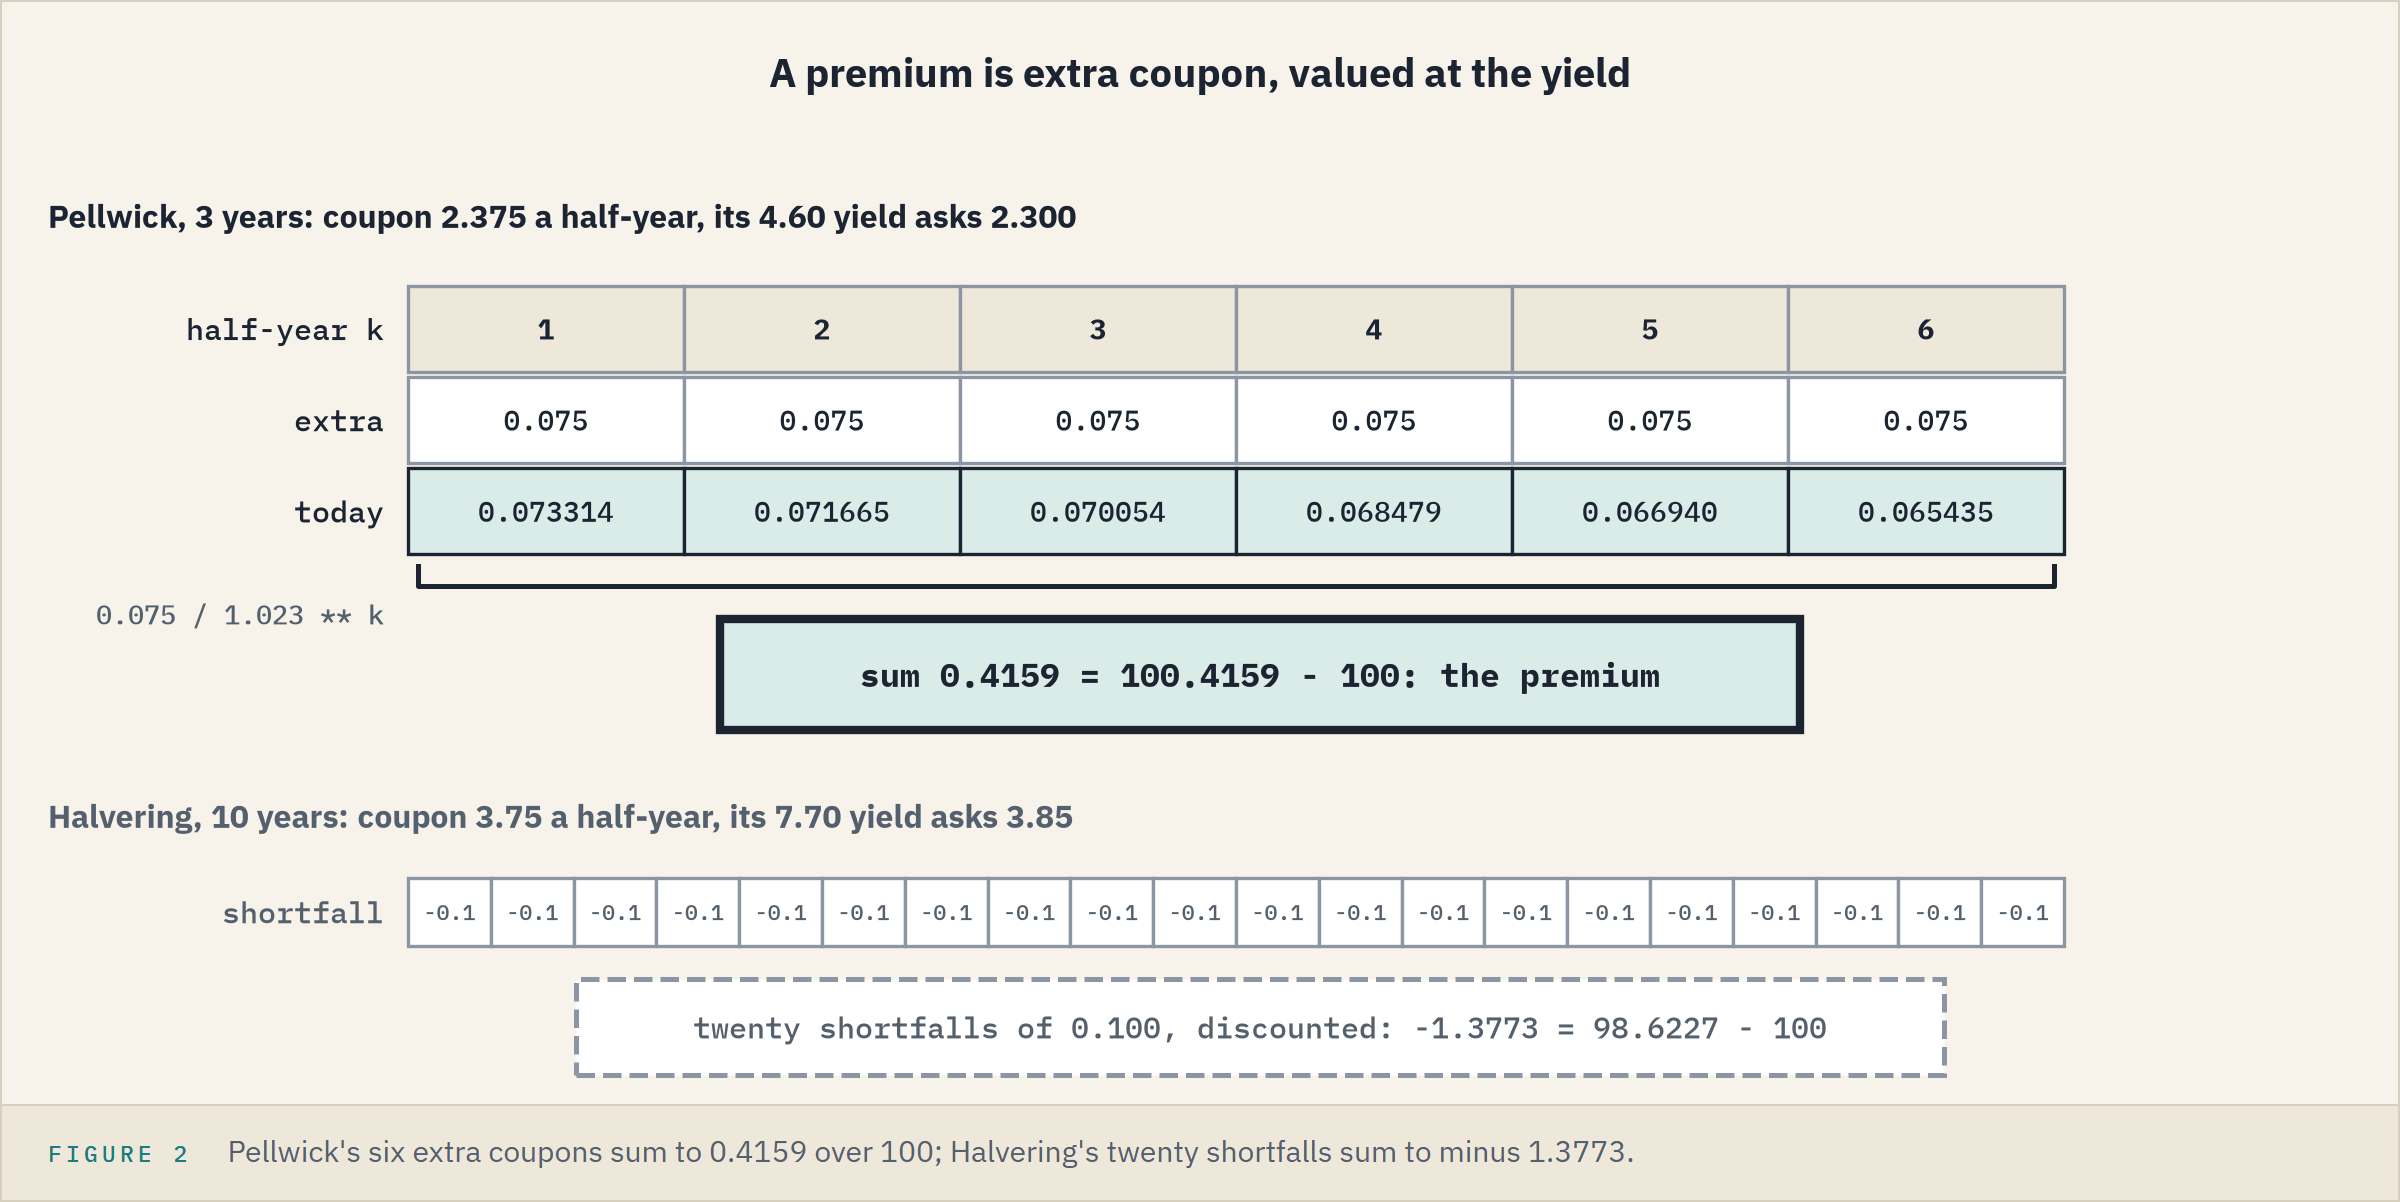

Pellwick's six extras are worth 0.415887 today: its premium, to the last digit.
Halvering's twenty shortfalls cost 1.377264: its discount.

**Predict 1**

Q. Give Dunmarrow a coupon one point above its 6.125 yield: 7.125.
Over 1 year that extra point is worth 0.9559.
Keep the coupon and the yield; over 30 years, what is it worth?
Write down a number.

### One Point of Coupon, Any Term

In [7]:
for years in [1, 2, 3, 5, 7, 10, 20, 30]:
    # one point of extra coupon, valued at the yield
    premium = bondmath.price_from_yield(7.125, 6.125, years) - 100
    # Dunmarrow's own coupon, equal to its yield
    at_own_coupon = bondmath.price_from_yield(6.125, 6.125, years)
    print(f'{years:>2} years: premium {premium:.4f}; own coupon {at_own_coupon:.6f}')

 1 years: premium 0.9559; own coupon 100.000000
 2 years: premium 1.8558; own coupon 100.000000
 3 years: premium 2.7030; own coupon 100.000000
 5 years: premium 4.2515; own coupon 100.000000
 7 years: premium 5.6240; own coupon 100.000000
10 years: premium 7.3959; own coupon 100.000000
20 years: premium 11.4415; own coupon 100.000000
30 years: premium 13.6544; own coupon 100.000000


13.6544 at 30 years: about 14 times the 1-year premium, not 30, because later extras are discounted harder.
A coupon equal to the yield prices at 100 at every term, which is why a new bond's coupon is set near the yield: it comes to market near par.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The label, price in A2</td><td align="left">nested <code>np.where</code></td><td align="left"><code>=IF(ROUND(A2,6)&gt;100,"premium",IF(ROUND(A2,6)&lt;100,"discount","par"))</code></td><td align="left">premium, par, discount for Pellwick, Dunmarrow, Quorvane</td></tr>
<tr><td align="left">Pellwick's extra coupons</td><td align="left"><code>extra_pv</code></td><td align="left"><code>=-PV(4.6/100/2,2*3,(4.75-4.6)/2,0)</code></td><td align="left">0.415887</td></tr>
<tr><td align="left">Coupon at the yield, 30 years</td><td align="left"><code>price_from_yield(6.125, 6.125, 30)</code></td><td align="left"><code>=-PV(6.125/100/2,2*30,6.125/2,100)</code></td><td align="left">100</td></tr>
</table>
<br clear="left">

With a last argument of 0, `-PV` values the payments alone, as notebook 02's coupons-alone row did.

**A premium is extra coupon, valued at the yield; a discount is the shortfall. The coupon decides the side of 100, the term how far.**

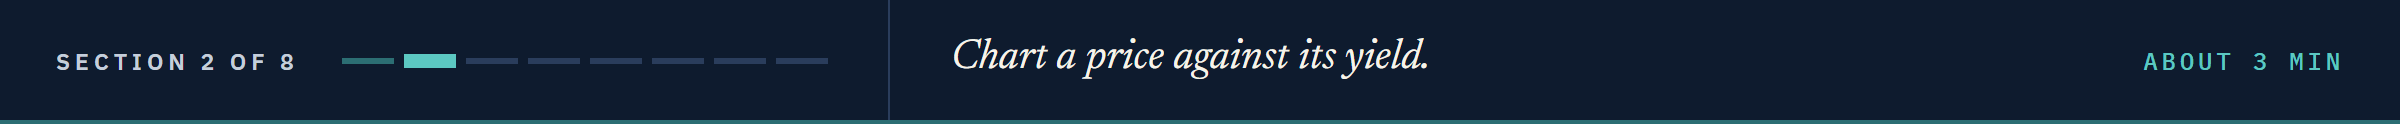

## 3.2 The Price-Yield Curve, Charted

Yields move, and prices follow.
A desk counts the move in basis points: 100 bp is 1 point of yield.

**Predict 2**

Q. From today, Quorvane's yield falls 100 bp; or, from today, it rises 100 bp. Compare the price's gain with its loss.

A) the gain and the loss are equal
B) the gain is larger
C) the loss is larger

### Quorvane at Seven Yields

In [8]:
grid = pd.DataFrame({'yield_pct': [2.4, 3.4, 4.4, 5.4, 6.4, 7.4, 8.4]})
grid['price'] = [bondmath.price_from_yield(5.25, y, 5) for y in grid['yield_pct']]
# the move from today's price, in points per 100 of face
grid['change'] = grid['price'] - bonds.loc[0, 'price']
formats = {'yield_pct': '{:.2f}', 'price': '{:.4f}', 'change': '{:+.4f}'}
grid.style.format(formats).hide(axis='index')

yield_pct,price,change
2.40,113.3529,+14.0026
3.40,108.4408,+9.0905
4.40,103.7780,+4.4276
5.40,99.3503,+0.0000
6.40,95.1448,-4.2055
7.40,91.1491,-8.2012
8.40,87.3516,-11.9987


B: 100 bp down gains 4.4276, 100 bp up loses only 4.2055.
Each step to the right moves the price less than the one before.

### Excel's PRICE Column, Row for Row

Q. Does the module agree with Excel's `PRICE` on all seven yields?

In [9]:
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
# a label slice keeps its end: rows 01 to 07
grid['excel'] = tvm.loc['tvm_price_01':'tvm_price_07', 'excel_value'].to_numpy()
gap = (grid['price'] - grid['excel']).abs().max()
assert gap < 1e-9
# :.1e writes a number in scientific form
print(f'Seven PRICE rows, largest gap {gap:.1e} per 100 of face')

Seven PRICE rows, largest gap 5.7e-14 per 100 of face


**Your module and Excel's `PRICE` give the same column: the largest gap is in the fourteenth decimal.**

### Every Bond's Curve

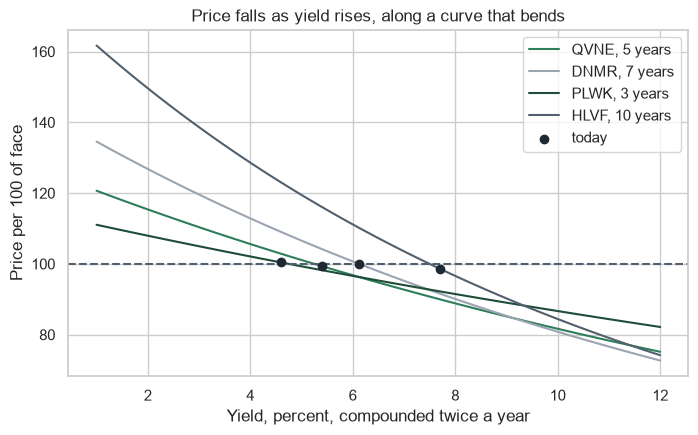

In [10]:
yield_axis = np.linspace(1, 12, 111)
fig, ax = plt.subplots(figsize=(8, 4.5))
for ticker, c, t in zip(bonds['ticker'], bonds['coupon_pct'], bonds['years']):
    ax.plot(yield_axis, [bondmath.price_from_yield(c, y, t) for y in yield_axis],
            label=f'{ticker}, {t} years')
ax.scatter(bonds['yield_pct'], bonds['price'], color='#1F2933', zorder=3, label='today')
ax.axhline(100, color='#52606D', linestyle='--')
ax.set_title('Price falls as yield rises, along a curve that bends')
ax.set_xlabel('Yield, percent, compounded twice a year')
ax.set_ylabel('Price per 100 of face')
ax.legend()
plt.show()

Every curve slopes down and bends, steeper at low yields: that bend is **convexity**, and notebook 10 measures it.
Each crosses 100 where the yield equals its coupon, 3.1's rule on a chart.
Halvering, the longest, is the steepest.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The column</td><td align="left"><code>grid['price']</code></td><td align="left"><code>yield_pct</code> and <code>price</code> in A1:B1, 2.4 to 8.4 in A2:A8, <code>=PRICE(DATE(2026,9,30),DATE(2031,9,30),5.25/100,A2/100,100,2,0)</code> in B2, filled to B8</td><td align="left">113.352941 to 87.351584</td></tr>
<tr><td align="left">The chart</td><td align="left"><code>ax.plot</code></td><td align="left">select A1:B8, then Insert, Scatter with Straight Lines</td><td align="left">one line, named <code>price</code></td></tr>
</table>
<br clear="left">

**Price falls as yield rises, along a curve: 100 bp down gains more than 100 bp up loses.**

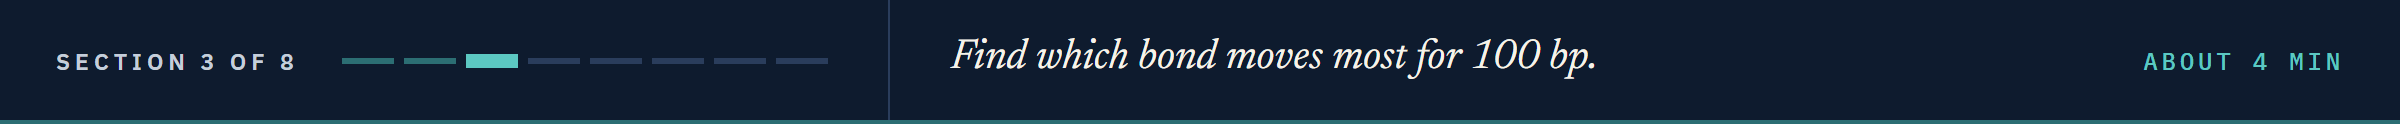

## 3.3 Coupon and Maturity: Which Bond Moves More

A steeper curve means a bigger move for the same 100 bp.

### 100 bp Each Way, Four Bonds

Q. How far does each price move, in percent, when its yield falls or rises 100 bp?

In [11]:
terms = list(zip(bonds['coupon_pct'], bonds['yield_pct'], bonds['years']))
bonds['down'] = [bondmath.price_from_yield(c, y - 1, t) for c, y, t in terms]
bonds['up'] = [bondmath.price_from_yield(c, y + 1, t) for c, y, t in terms]
bonds['down_pct'] = (bonds['down'] - bonds['price']) / bonds['price'] * 100
bonds['up_pct'] = (bonds['up'] - bonds['price']) / bonds['price'] * 100
moves = bonds.sort_values('years')[['ticker', 'years', 'coupon_pct', 'down_pct', 'up_pct']]
formats = {'coupon_pct': '{:.3f}', 'down_pct': '{:+.2f}', 'up_pct': '{:+.2f}'}
moves.style.format(formats).hide(axis='index')

ticker,years,coupon_pct,down_pct,up_pct
PLWK,3,4.750,+2.82,-2.72
QVNE,5,5.250,+4.46,-4.23
DNMR,7,6.125,+5.82,-5.44
HLVF,10,7.500,+7.24,-6.62


`list()` keeps the pairs from `zip`: a bare `zip` can be read only once, and two comprehensions read it.

### Against Excel's Eight PRICE Rows

In [12]:
# Excel's PRICE 100 bp down and 100 bp up, in the bonds' order
down_rows = ['tvm_price_03', 'tvm_price_08', 'tvm_price_10', 'tvm_price_12']
up_rows = ['tvm_price_05', 'tvm_price_09', 'tvm_price_11', 'tvm_price_13']
assert (bonds['down'] - tvm.loc[down_rows, 'excel_value'].to_numpy()).abs().max() < 1e-9
assert (bonds['up'] - tvm.loc[up_rows, 'excel_value'].to_numpy()).abs().max() < 1e-9
print('All eight moved prices match Excel')

All eight moved prices match Excel


Pellwick, 3 years, loses 2.72 percent for 100 bp up; Halvering, 10 years, 6.62.
Every bond gains more than it loses: the bend, on all four.
But the four differ in coupon and maturity at once, so move one lever at a time.

### One Lever at a Time: Maturity

Q. Keep Quorvane's 5.25 coupon and 5.40 yield, and change only the maturity.

In [13]:
maturity_table = pd.DataFrame({'years': [1, 2, 3, 5, 7, 10, 20, 30]})
term_years = maturity_table['years']
maturity_table['price'] = [bondmath.price_from_yield(5.25, 5.4, t) for t in term_years]
maturity_table['up'] = [bondmath.price_from_yield(5.25, 6.4, t) for t in term_years]
maturity_table['up_pct'] = ((maturity_table['up'] - maturity_table['price'])
                            / maturity_table['price'] * 100)
maturity_table.round(2).T

,0,1,2,3,4,5,6,7
years,1.00,2.00,3.00,5.00,7.00,10.00,20.00,30.00
price,99.86,99.72,99.59,99.35,99.14,98.85,98.18,97.78
up,98.90,97.87,96.91,95.14,93.59,91.60,87.13,84.75
up_pct,-0.95,-1.85,-2.70,-4.23,-5.59,-7.34,-11.26,-13.33


### One Lever at a Time: Coupon

Q. Keep 5 years and the 5.40 yield, and change only the coupon.

In [14]:
coupon_table = pd.DataFrame({'coupon_pct': [0, 2.5, 5.25, 8, 10.5]})
coupons = coupon_table['coupon_pct']
coupon_table['price'] = [bondmath.price_from_yield(c, 5.4, 5) for c in coupons]
coupon_table['up'] = [bondmath.price_from_yield(c, 6.4, 5) for c in coupons]
coupon_table['up_pct'] = ((coupon_table['up'] - coupon_table['price'])
                          / coupon_table['price'] * 100)
coupon_table.round(4).T

,0,1,2,3,4
coupon_pct,0.0000,2.5000,5.2500,8.0000,10.5000
price,76.6118,87.4397,99.3503,111.2610,122.0889
up,72.9799,83.5346,95.1448,106.7550,117.3098
up_pct,-4.7407,-4.4660,-4.2330,-4.0499,-3.9144


The zero coupon's 76.6118 is notebook 01's value of the 100 alone; 10.50's 122.0889 is notebook 02's Predict 3.

### Both Levers, Side by Side

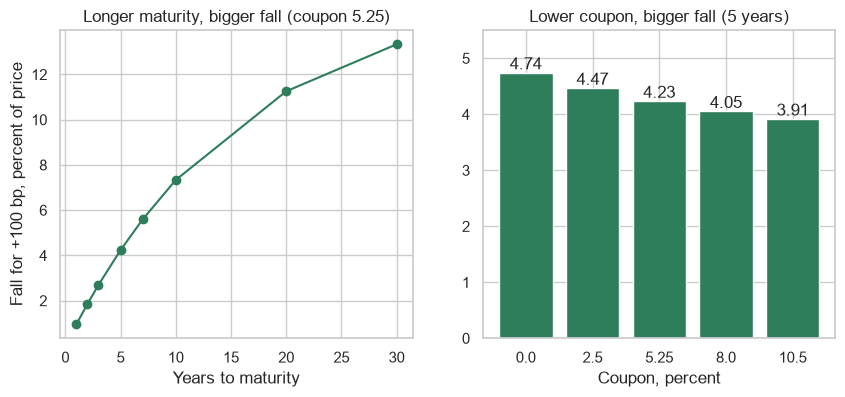

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(maturity_table['years'], -maturity_table['up_pct'], marker='o')
axes[0].set_title('Longer maturity, bigger fall (coupon 5.25)')
axes[0].set_xlabel('Years to maturity')
axes[0].set_ylabel('Fall for +100 bp, percent of price')
# astype(str) turns each coupon into text, one label per bar
bars = axes[1].bar(coupon_table['coupon_pct'].astype(str), -coupon_table['up_pct'])
axes[1].bar_label(bars, fmt='%.2f')
axes[1].set_ylim(0, 5.5)
axes[1].set_title('Lower coupon, bigger fall (5 years)')
axes[1].set_xlabel('Coupon, percent')
plt.show()

Thirty years falls 13.33 percent, not thirty times the 1-year 0.95.
The zero coupon falls most, 4.74 percent; the 10.50 coupon least, 3.91.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Halvering, 100 bp up</td><td align="left"><code>bonds.loc[3, 'up']</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2036,9,30),7.5/100,8.7/100,100,2,0)</code></td><td align="left">92.092797</td></tr>
<tr><td align="left">Halvering, 100 bp down</td><td align="left"><code>bonds.loc[3, 'down']</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2036,9,30),7.5/100,6.7/100,100,2,0)</code></td><td align="left">105.762901</td></tr>
<tr><td align="left">The change in percent</td><td align="left"><code>bonds.loc[3, 'up_pct']</code></td><td align="left">today's <code>PRICE</code> (7.7/100) in B1, the 8.7/100 one in B2, <code>=(B2-B1)/B1*100</code></td><td align="left">-6.62</td></tr>
</table>
<br clear="left">

**A longer maturity and a lower coupon both mean a bigger move: both push the cash later. Notebook 09 puts one number on it.**

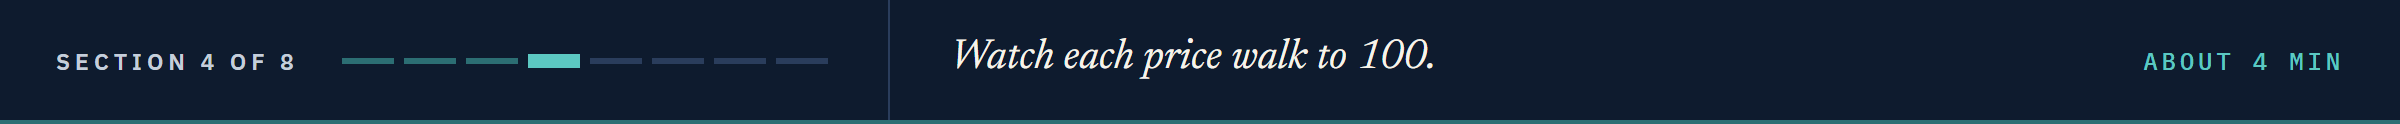

## 3.4 Pull to Par on Coupon Dates

A bond repays 100 at maturity, whatever it costs today.
Hold the yield, and the price must walk to 100: the **pull to par**.

### Four Prices Walk to 100

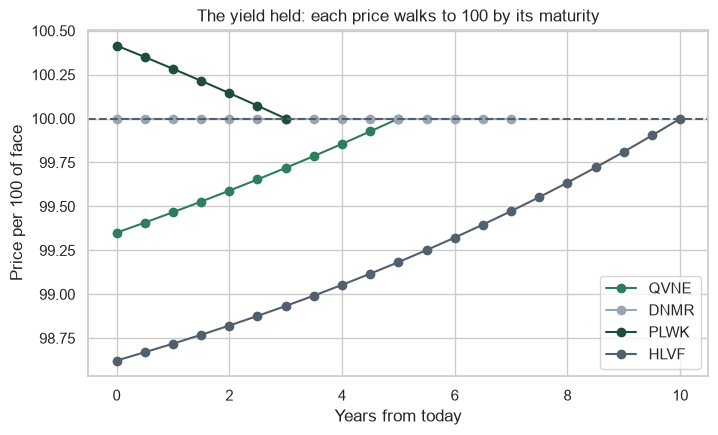

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for ticker, c, y, t in zip(bonds['ticker'], bonds['coupon_pct'], bonds['yield_pct'],
                           bonds['years']):
    # the price on each coupon date, the yield held; + joins two lists: the 100 at maturity last
    times = [k / 2 for k in range(2 * t)]
    path = [bondmath.price_from_yield(c, y, t - time) for time in times]
    ax.plot(times + [t], path + [100], marker='o', label=ticker)
ax.axhline(100, color='#52606D', linestyle='--')
ax.set_title('The yield held: each price walks to 100 by its maturity')
ax.set_xlabel('Years from today')
ax.set_ylabel('Price per 100 of face')
ax.legend()
plt.show()

Pellwick, the premium, walks down; Quorvane and Halvering walk up; Dunmarrow stays on the line.
Every move on the chart is time passing: the yield never moved.

### Halvering's Walk

In [17]:
for years_left in [10, 9.5, 5, 0.5]:
    walk_price = bondmath.price_from_yield(7.5, 7.7, years_left)
    print(f'{years_left:>4} years left: {walk_price:.4f}')

  10 years left: 98.6227
 9.5 years left: 98.6697
   5 years left: 99.1828
 0.5 years left: 99.9037


The first half-year adds 0.0470; the last, from 99.9037 to 100, adds 0.0963.
The walk quickens: the nearer the price is to 100, the nearer each half-year's climb comes to the full shortfall of 0.100.

**Predict 3**

Q. Halvering's yield stays at 7.70.
Over the next half-year it collects its 3.75 coupon and climbs 0.0470.
What does it earn, as a percent of today's 98.6227?
Write down a number.

### What a Half-Year Earns

In [18]:
bonds['pull'] = [bondmath.price_from_yield(c, y, t - 0.5) - p for c, y, t, p in
                 zip(bonds['coupon_pct'], bonds['yield_pct'], bonds['years'], bonds['price'])]
# coupon plus pull, as a percent of today's price
bonds['return_pct'] = (bonds['coupon_pct'] / 2 + bonds['pull']) / bonds['price'] * 100
assert (bonds['return_pct'] - bonds['yield_pct'] / 2).abs().max() < 1e-9
bonds[['ticker', 'coupon_pct', 'yield_pct', 'pull', 'return_pct']].round(6)

,ticker,coupon_pct,yield_pct,pull,return_pct
0,QVNE,5.250,5.400,0.057459,2.7000
1,DNMR,6.125,6.125,0.000000,3.0625
2,PLWK,4.750,4.600,-0.065435,2.3000
3,HLVF,7.500,7.700,0.046975,3.8500


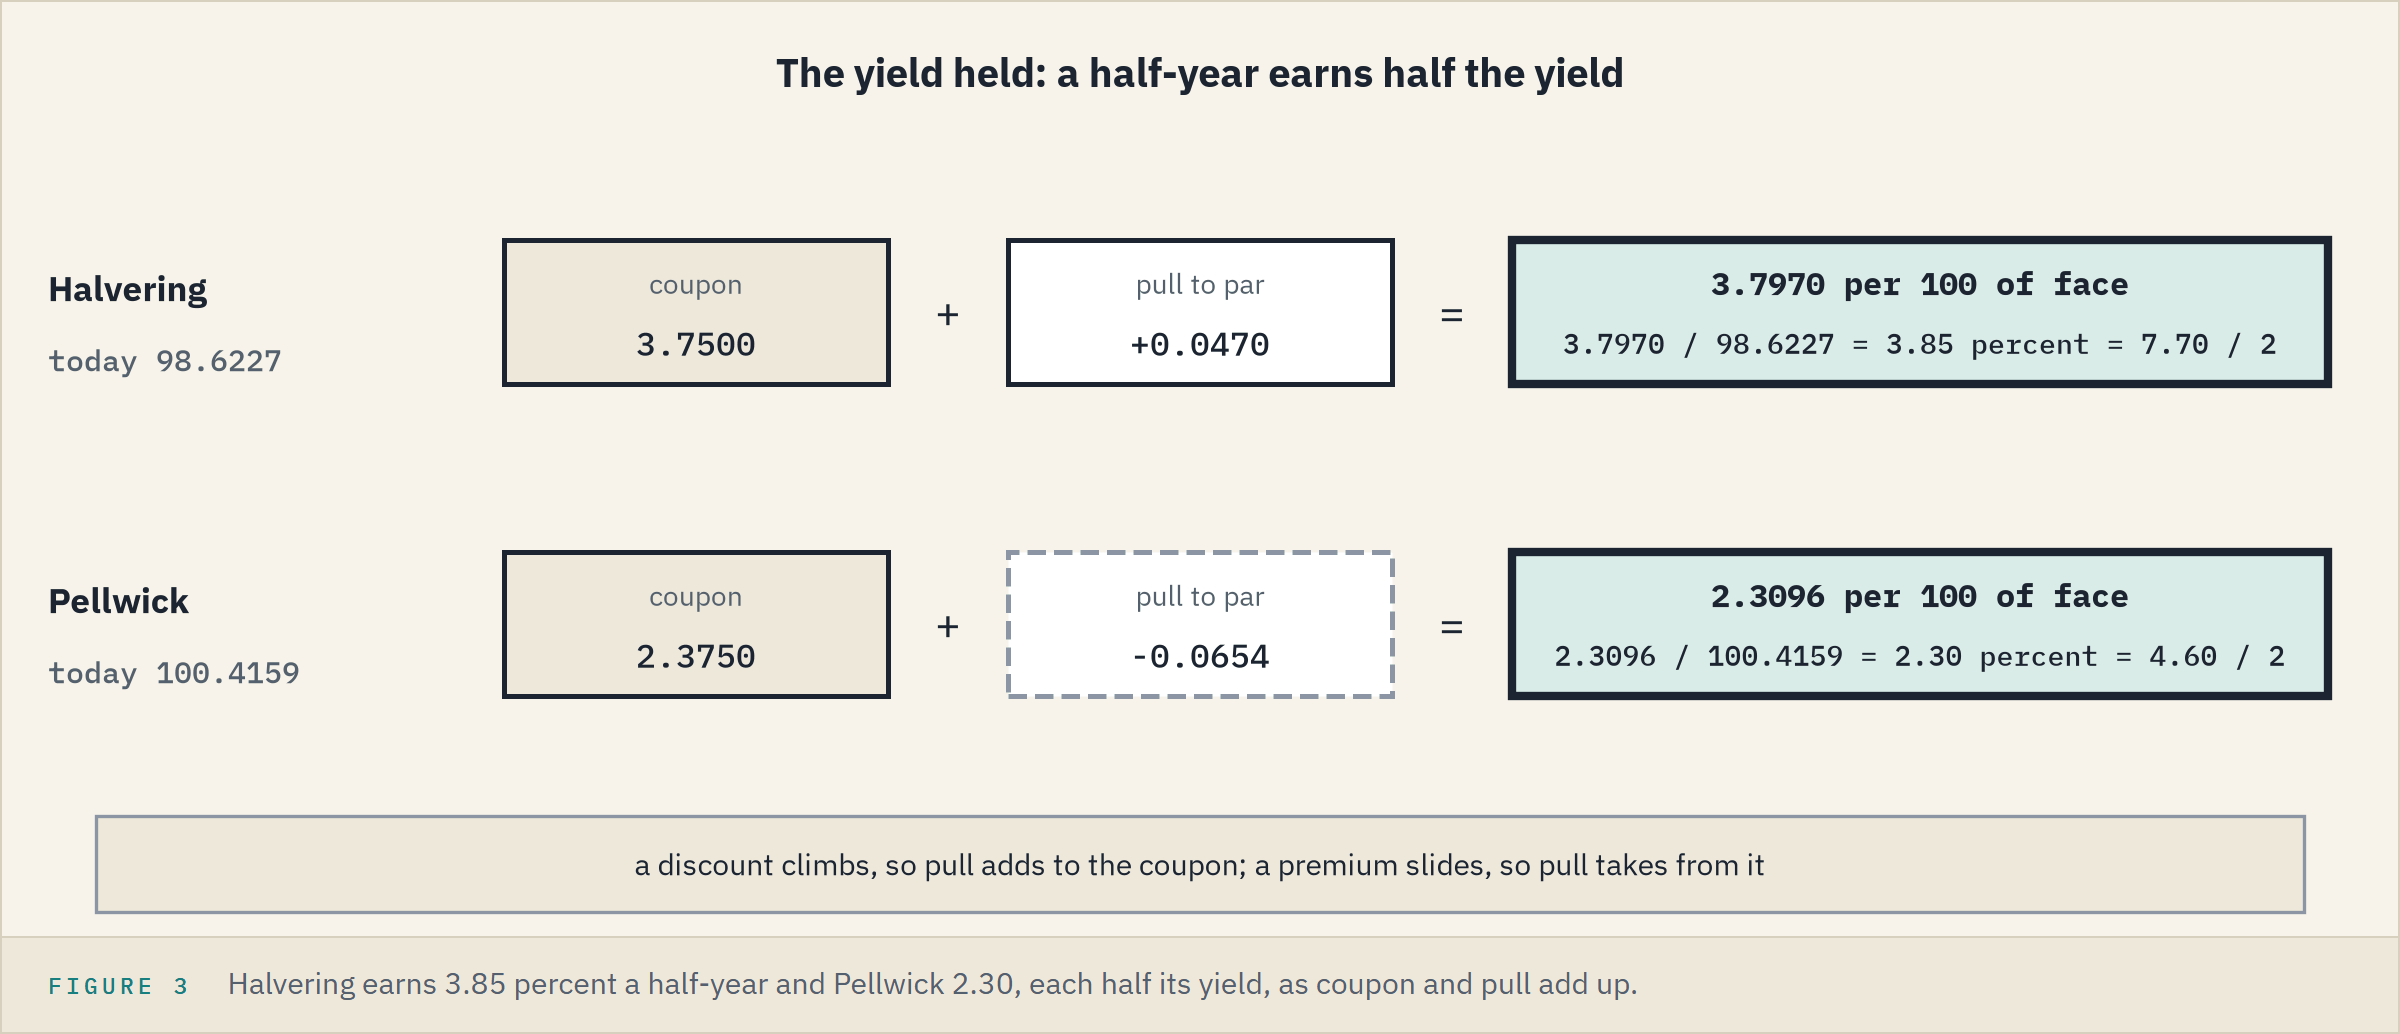

Halvering earns 3.85 percent, half its 7.70 yield: part coupon, part pull.
Pellwick's pull is negative, -0.065435, and its coupon covers it: 2.30 percent, half its 4.60.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Halvering's walk</td><td align="left"><code>price_from_yield(7.5, 7.7, years_left)</code></td><td align="left">10 down to 0.5 in A1:A20, <code>=-PV(7.7/100/2,2*A1,7.5/2,100)</code> in B1, filled to B20</td><td align="left">98.622736 to 99.903707</td></tr>
<tr><td align="left">Pellwick's walk</td><td align="left"><code>price_from_yield(4.75, 4.6, years_left)</code></td><td align="left">3 down to 0.5 in A1:A6, <code>=-PV(4.6/100/2,2*A1,4.75/2,100)</code> in B1, filled to B6</td><td align="left">100.415887 to 100.073314</td></tr>
</table>
<br clear="left">

**If the yield does not move, the bond earns its yield: part coupon, part pull to par.**

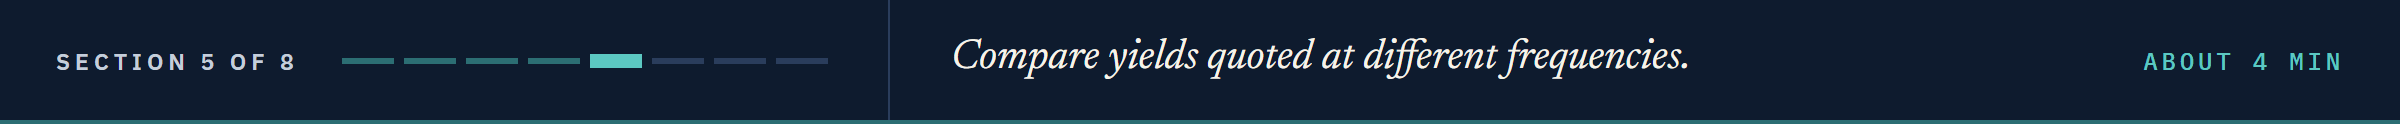

## 3.5 One Yield, Three Quotes

Quorvane's 5.40 compounds twice a year: 2.70 percent a half-year.
The dealer's 5.45 compounds once a year.

**Predict 4**

Q. The dealer's annual-pay bond at 5.45, or Quorvane at 5.40 semiannual: which yields more?

A) the annual-pay bond: 5.45 is the bigger number
B) Quorvane
C) they yield the same

### One Year's Growth

Two yields compare only when they grow 100 to the same amount in a year.

Q. What does 100 grow to in one year at 5.40 percent, compounded twice?

In [19]:
growth = 100 * (1 + 5.4 / 100 / 2) ** 2
# compounded once a year, the rate is the growth above 100
annual_pct = growth - 100
print(f'100 grows to {growth:.4f}: {annual_pct:.4f} percent compounded once a year')

100 grows to 105.4729: 5.4729 percent compounded once a year


The second half-year earns interest on the first half-year's interest.
Notebook 01's One Rate, Three Frequencies held the rate and let the growth change; here the growth holds and the rate changes.

### Four Times a Year

The quarterly rate q must grow 1 to the same 1.054729 in four steps: (1 + q) ** 4 = 1.054729.
So 1 + q is the fourth root of 1.054729, and `** (1 / 4)` takes it, as Excel's `^(1/4)` does.

In [20]:
# the quarterly rate that matches the growth, times 4 for the annual quote
quarterly_pct = ((growth / 100) ** (1 / 4) - 1) * 4 * 100
print(f'Quarterly: {quarterly_pct:.6f} percent')

Quarterly: 5.364034 percent


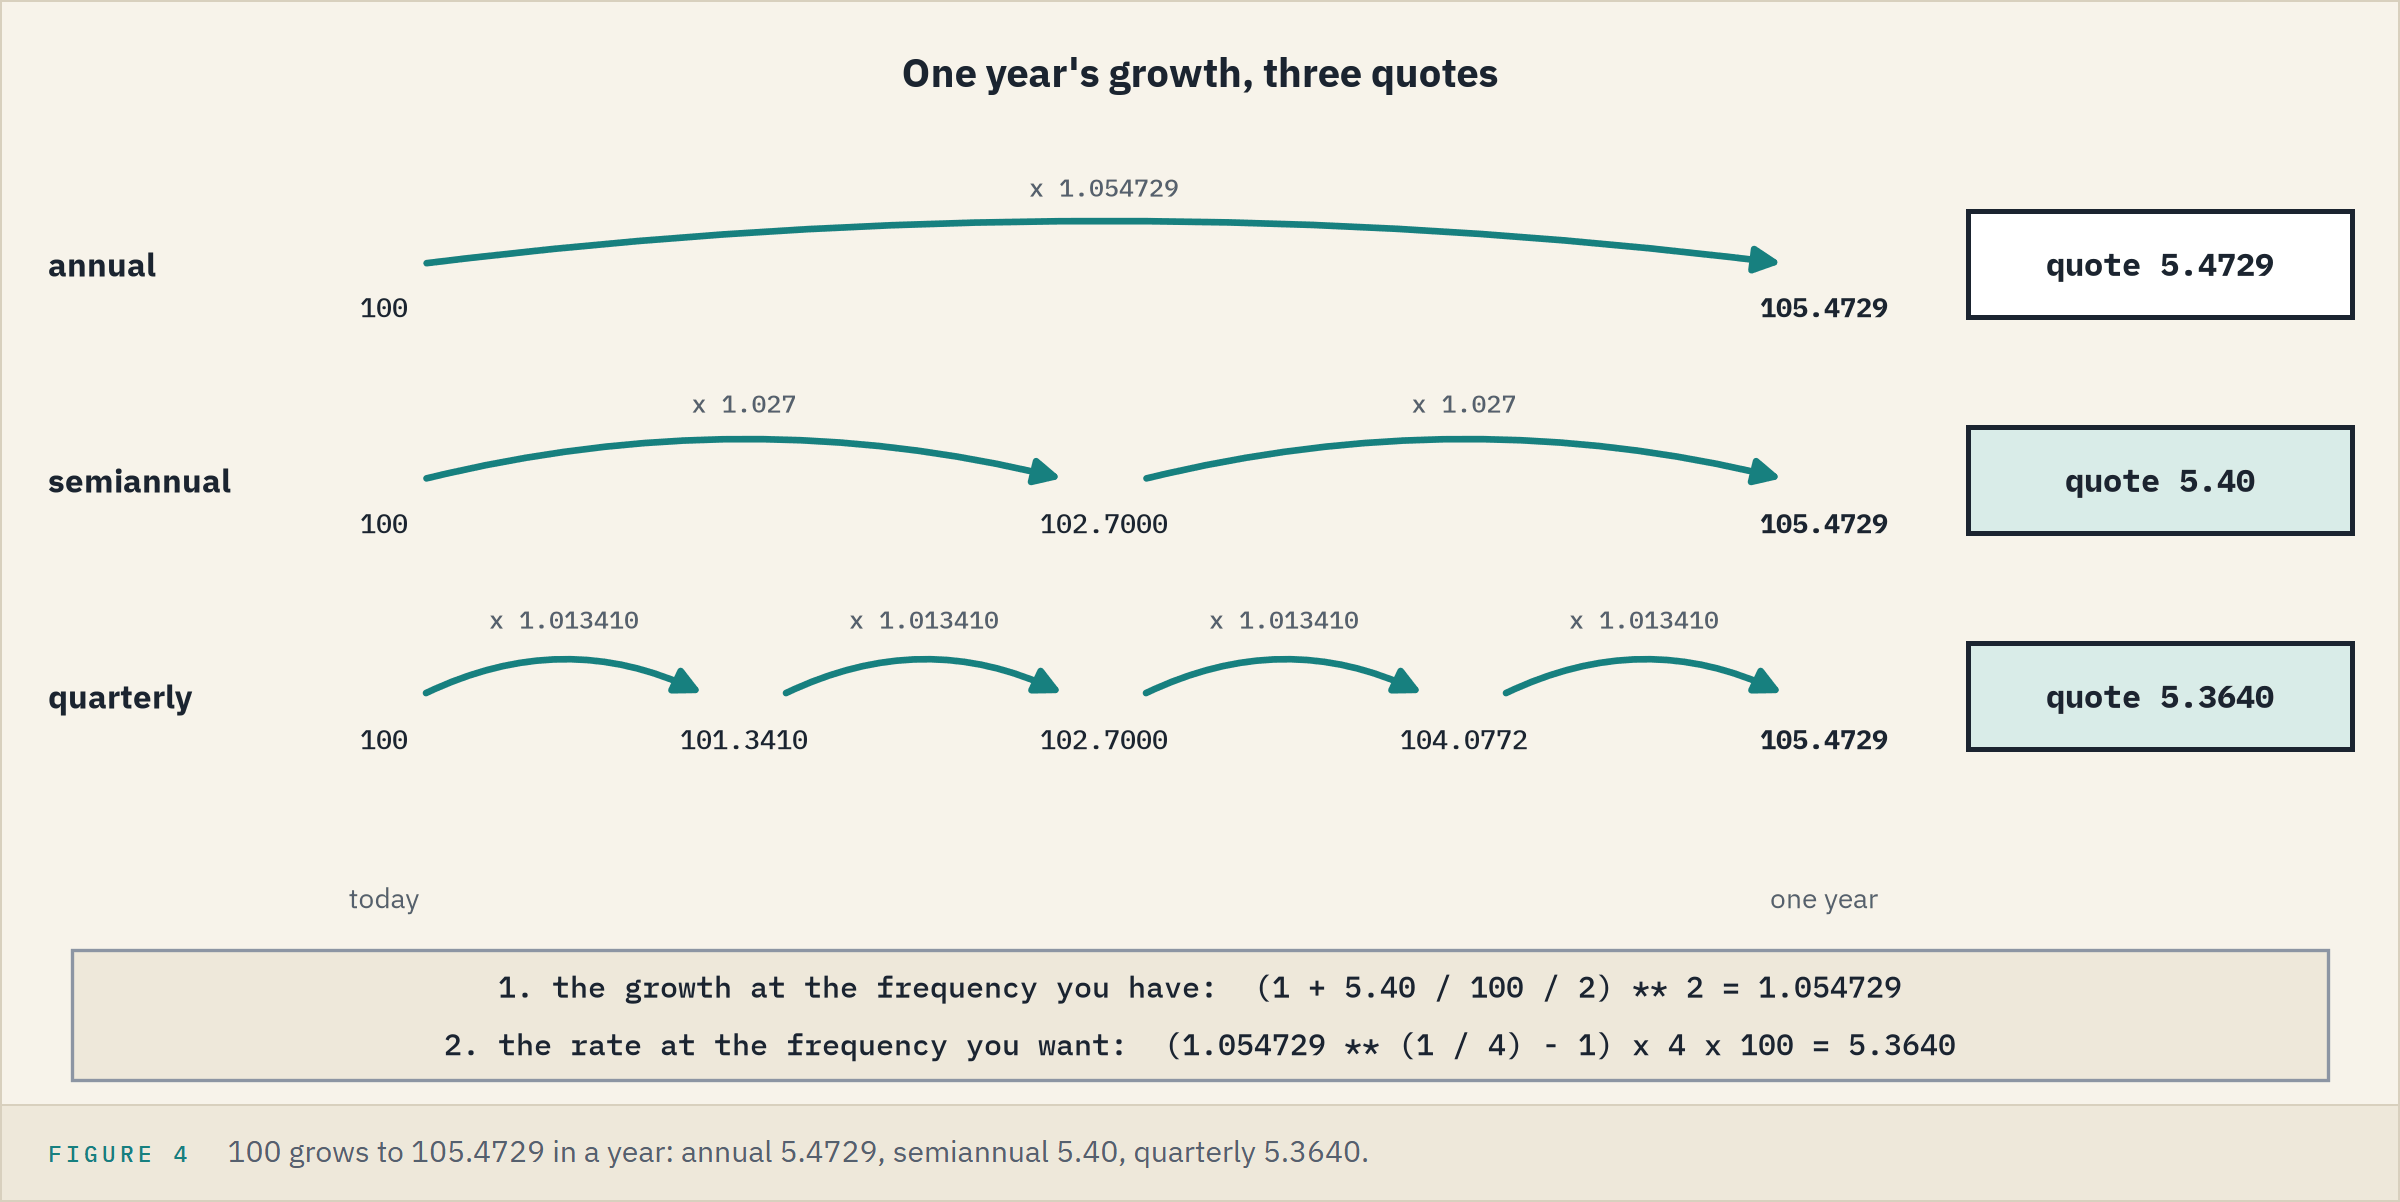

Compounding more often needs a lower quote for the same growth: 5.4729 annual, 5.40 semiannual, 5.3640 quarterly.

### The Dealer's 5.45

Q. Put the two quotes on one footing, both ways round.

In [21]:
# the dealer's 5.45 restated twice a year: the half-year rate whose two steps match its growth
dealer_semiannual = ((1 + 5.45 / 100) ** (1 / 2) - 1) * 2 * 100
print(f'Annual: Quorvane {annual_pct:.4f}, the dealer 5.4500')
print(f'Semiannual: Quorvane 5.4000, the dealer {dealer_semiannual:.4f}')

Annual: Quorvane 5.4729, the dealer 5.4500
Semiannual: Quorvane 5.4000, the dealer 5.3777


B: on either footing Quorvane yields more, though its quote is the smaller number.

**Excel side by side.** `EFFECT` restates a rate compounded `npery` times a year as an annual rate, and `NOMINAL` goes the other way; both take and return decimals.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">One year's growth</td><td align="left"><code>growth</code></td><td align="left"><code>=100*(1+5.4/100/2)^2</code></td><td align="left">105.4729</td></tr>
<tr><td align="left">The annual rate, written out</td><td align="left"><code>annual_pct</code></td><td align="left"><code>=((1+5.4/100/2)^2-1)*100</code></td><td align="left">5.4729</td></tr>
<tr><td align="left">The annual rate, one function</td><td align="left"><code>annual_pct / 100</code></td><td align="left"><code>=EFFECT(5.4/100,2)</code></td><td align="left">0.054729</td></tr>
<tr><td align="left">Quarterly, chained</td><td align="left"><code>quarterly_pct</code></td><td align="left"><code>=EFFECT(5.4/100,2)</code> in A1, then <code>=NOMINAL(A1,4)*100</code></td><td align="left">5.364033925063438</td></tr>
<tr><td align="left">Back to semiannual</td><td align="left">the quote we started from</td><td align="left"><code>=NOMINAL(A1,2)*100</code></td><td align="left">5.40</td></tr>
</table>
<br clear="left">

**Compare yields only at one frequency: Quorvane's 5.40 beats an annual 5.45.**

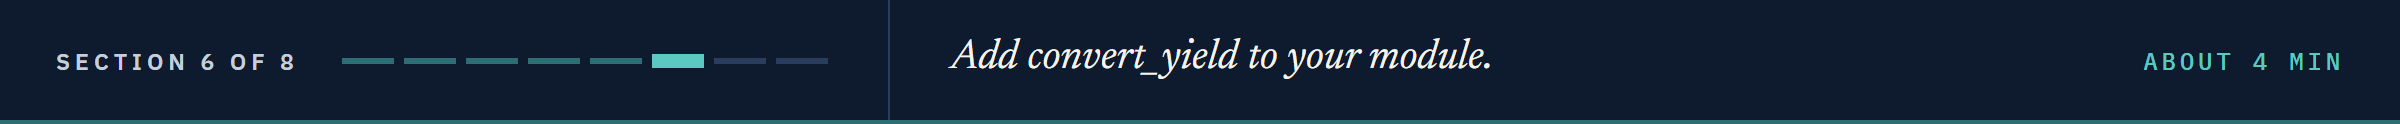

## 3.6 `convert_yield` in Your Module

The recipe never changes: one year's growth at the frequency you have, then the rate at the frequency you want.
Docstring first, as in notebook 01: the units, percent in and percent out; the convention, the same growth in one year; and the Excel functions.

### Append `convert_yield`

In [22]:
%%writefile -a bondmath.py


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100

Appending to bondmath.py


The loop checks both frequencies with the one test `cash_flows` uses.

### Reload and Restate the Four

In [23]:
import importlib

# read the file again: the module in memory has no convert_yield yet
importlib.reload(bondmath)
bonds['annual_pct'] = [bondmath.convert_yield(y, 2, 1) for y in bonds['yield_pct']]
bonds['quarterly_pct'] = [bondmath.convert_yield(y, 2, 4) for y in bonds['yield_pct']]
bonds[['ticker', 'annual_pct', 'yield_pct', 'quarterly_pct']].round(4)

,ticker,annual_pct,yield_pct,quarterly_pct
0,QVNE,5.4729,5.400,5.3640
1,DNMR,6.2188,6.125,6.0788
2,PLWK,4.6529,4.600,4.5738
3,HLVF,7.8482,7.700,7.6273


Quorvane's row is 3.5's two numbers.
Halvering's annual rate sits 0.1482 above its quote and Pellwick's only 0.0529: the gap grows with the yield.

### Two Tests

`EFFECT` rows go from `frequency` times a year to once: `convert_yield(rate, frequency, 1)`.
`NOMINAL` rows go the other way: `convert_yield(rate, 1, frequency)`.
Excel returns a decimal, so the expected value is Excel's times 100.
The round trip proves the two directions undo each other, not that either is right, so the Excel test comes first.

In [24]:
%%writefile -a test_bondmath.py


def test_convert_yield_matches_excel_effect_and_nominal():
    # EFFECT restates a rate compounded `frequency` times a year as an annually compounded rate
    for row in tvm_rows("EFFECT"):
        result = bondmath.convert_yield(float(row["rate_pct"]), int(row["frequency"]), 1)
        # Excel returns a decimal, bondmath a percent
        assert result == pytest.approx(float(row["excel_value"]) * 100, abs=1e-9), row["case_id"]
    # NOMINAL goes the other way: from annual compounding to `frequency` times a year
    for row in tvm_rows("NOMINAL"):
        result = bondmath.convert_yield(float(row["rate_pct"]), 1, int(row["frequency"]))
        assert result == pytest.approx(float(row["excel_value"]) * 100, abs=1e-9), row["case_id"]


def test_convert_yield_round_trip():
    # semiannual to quarterly and back gives the yield we started with
    quarterly = bondmath.convert_yield(6.0, 2, 4)
    assert bondmath.convert_yield(quarterly, 4, 2) == pytest.approx(6.0, abs=1e-12)

Appending to test_bondmath.py


### Run pytest

In [25]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........                                                                 [100%]
8 passed in 0.50s



### How Many Excel Numbers

In [26]:
effect_rows = tvm[tvm['function'] == 'EFFECT']
nominal_rows = tvm[tvm['function'] == 'NOMINAL']
both = pd.concat([effect_rows, nominal_rows])
print(len(effect_rows), 'EFFECT rows,', len(nominal_rows), 'NOMINAL rows')
print('Rates', both['rate_pct'].min(), 'to', both['rate_pct'].max(), 'percent; frequencies',
      sorted(both['frequency'].unique().tolist()))

16 EFFECT rows, 6 NOMINAL rows
Rates 0.5 to 10.25 percent; frequencies [1, 2, 4]


**Excel side by side.** Row `tvm_nominal_03` is `=NOMINAL(6.25/100,2)`, 0.061553; the test compares `convert_yield(6.25, 1, 2)` with 6.1553.

**`8 passed`: `convert_yield` agrees with Excel on all 22 rows.**

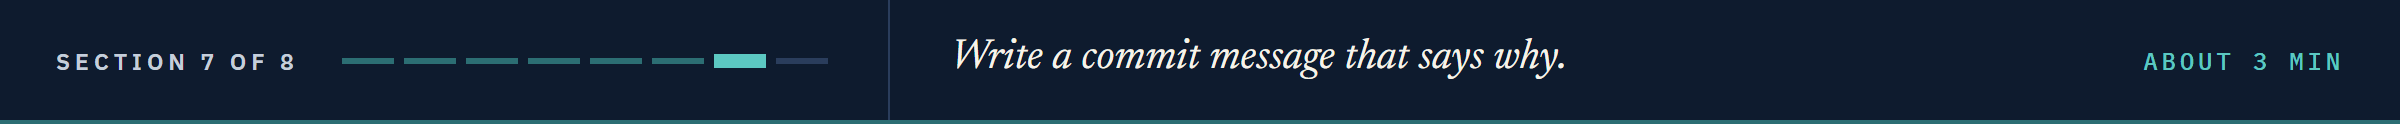

## 3.7 A Commit Message That Says Why

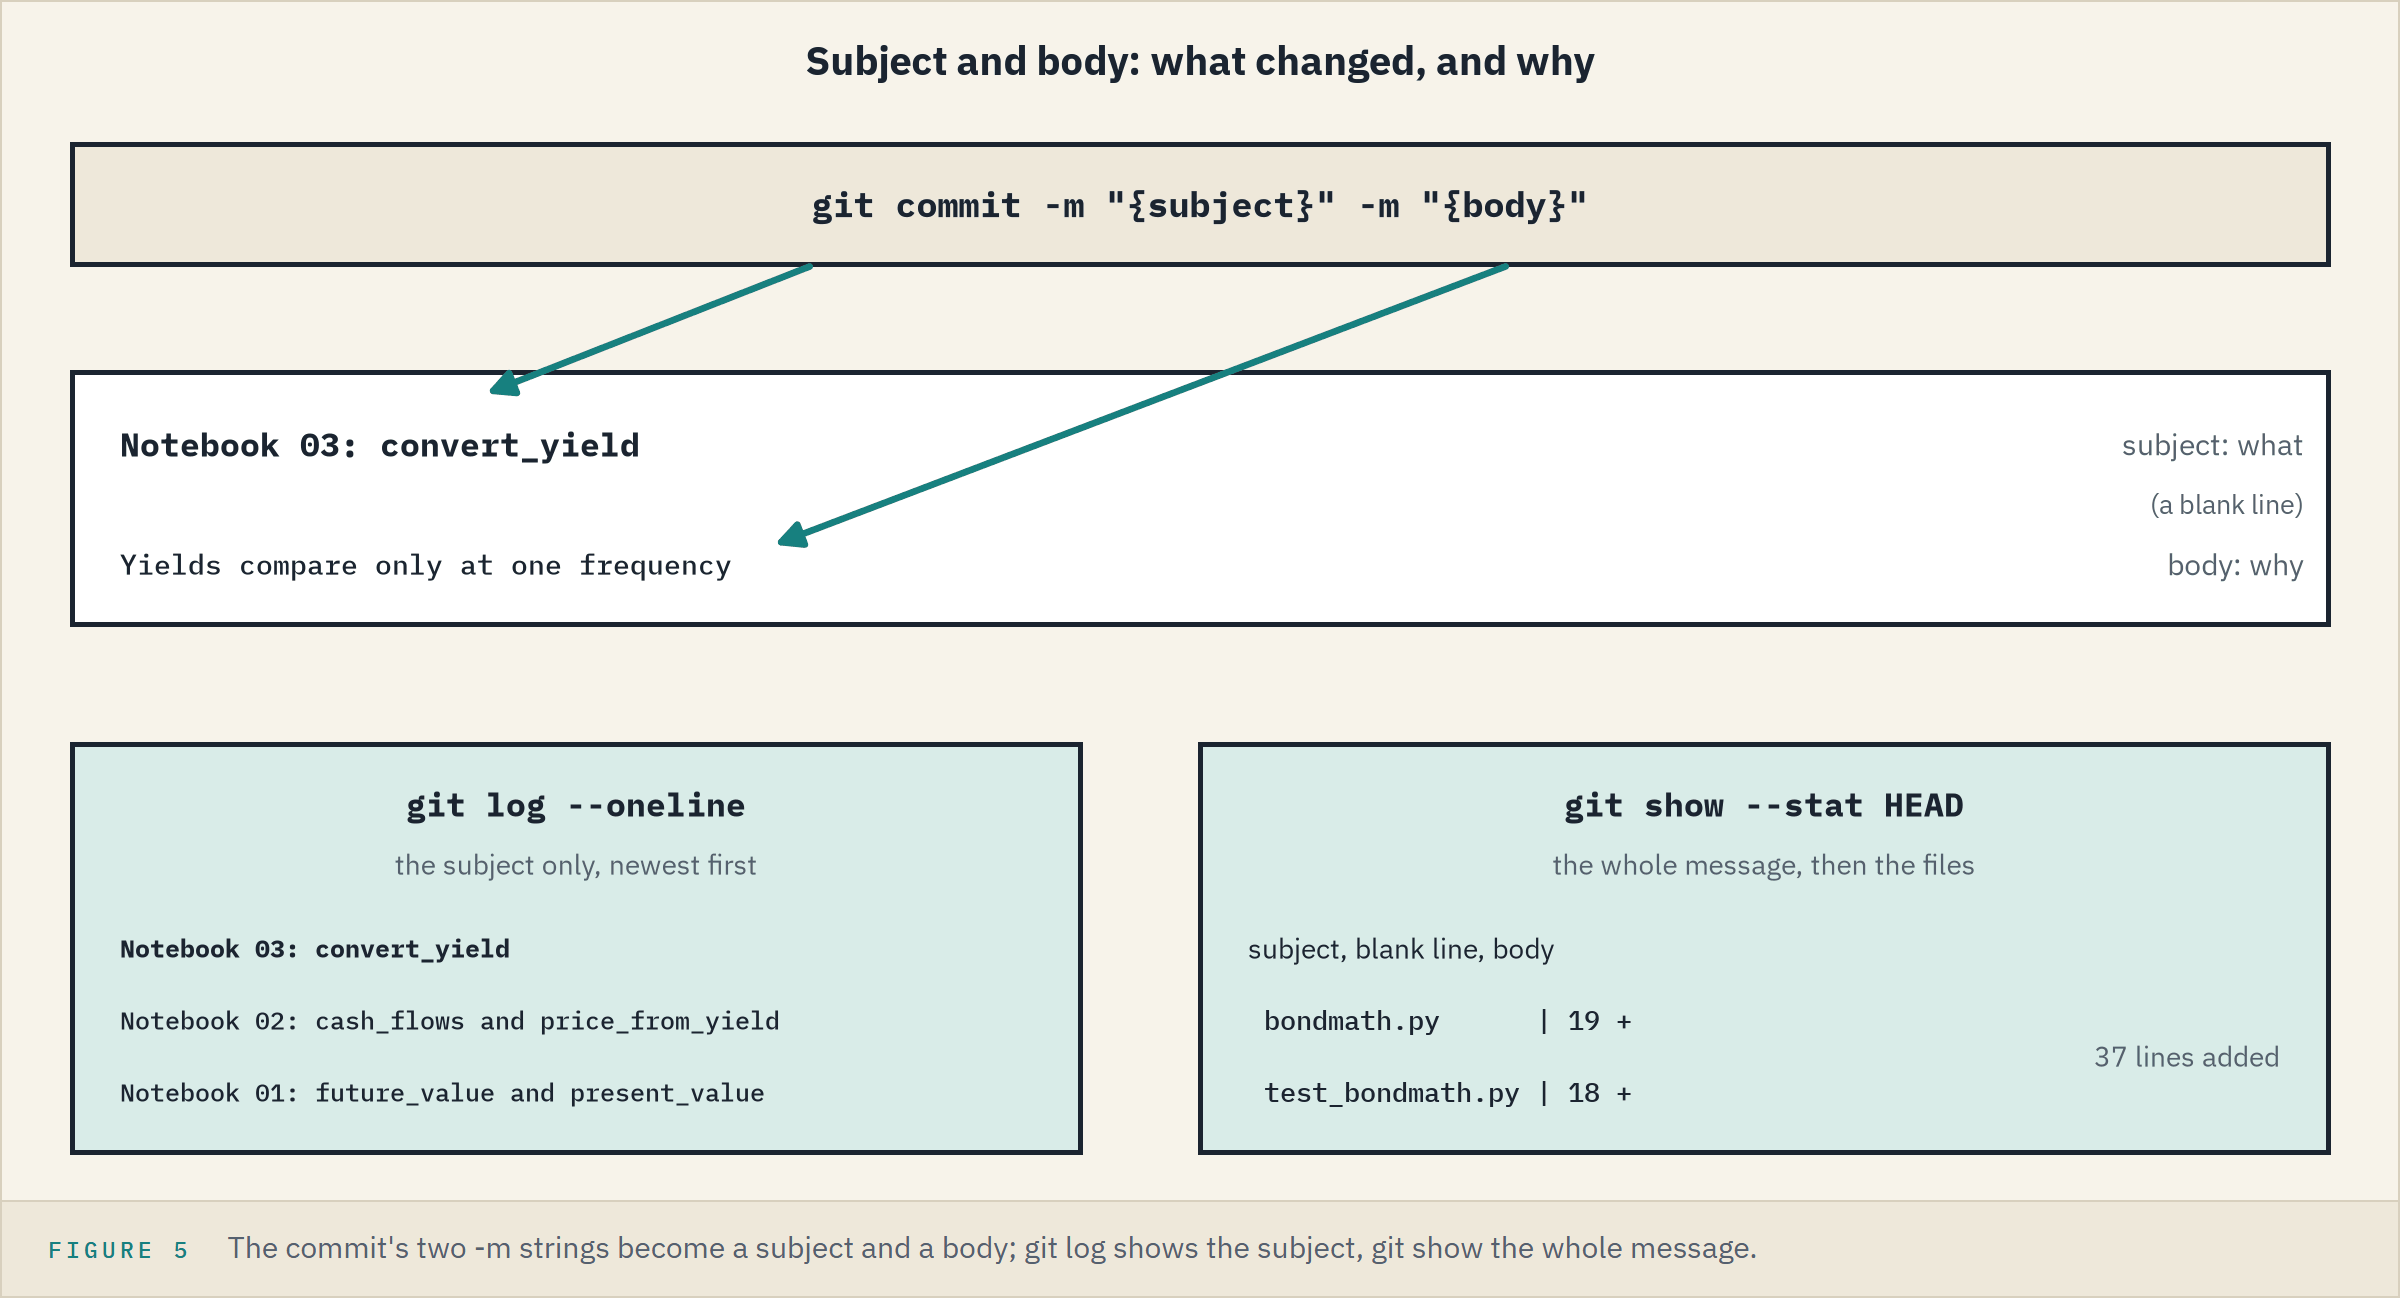

In six months `git log` is how you will find a change.
The first line, the **subject**, says what changed; the **body** says why.
`git commit` takes one `-m` for each: the first is the subject, the second the body.
As in notebook 01, `!` sends a line to the command line and `-C "{work}"` points Git at the work folder.

### What Changed

In [27]:
!git -C "{work}" diff --stat

 bondmath.py      | 19 +++++++++++++++++++
 test_bondmath.py | 18 ++++++++++++++++++
 2 files changed, 37 insertions(+)


Added lines only, as in notebook 02.

### Subject and Body

In [28]:
subject = 'Notebook 03: convert_yield'
body = 'Yields compare only at one frequency'
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -m "{subject}" -m "{body}"
!git -C "{work}" log --oneline

[main 4cdfc40] Notebook 03: convert_yield
 2 files changed, 37 insertions(+)
4cdfc40 Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


`{subject}` and `{body}` put the two names' text into the command, as `{work}` does.
`log --oneline` shows each subject alone, so the subject must say what on its own.

### The Whole Commit

In [29]:
# HEAD is the commit you are on; --stat lists the files it changed instead of every line
!git -C "{work}" show --stat HEAD

commit 4cdfc40e965b0b9ad7113135647f6be803252c86
Author: Course Student <student@example.com>
Date:   Wed Sep 30 09:00:00 2026 +0000

    Notebook 03: convert_yield
    
    Yields compare only at one frequency

 bondmath.py      | 19 +++++++++++++++++++
 test_bondmath.py | 18 ++++++++++++++++++
 2 files changed, 37 insertions(+)


Without `--stat`, `git show` prints the commit's whole diff.

**Three commits, each subject saying what changed; the body keeps the why for whoever reads it next.**

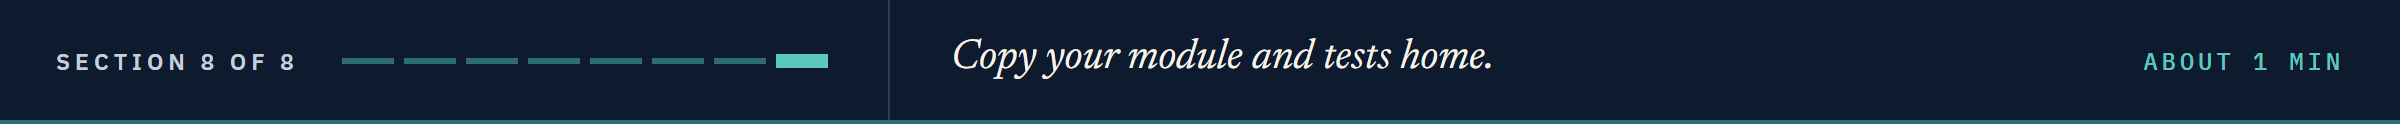

## Bring It Home

As in notebook 02, in a PowerShell terminal with the course's `.venv` active, with your own work folder.
The copy replaces your two files: anything you added by hand shows in `git diff --stat` as `-` lines, to read before you commit.

```powershell
# the work folder the setup cell printed
$work = "$env:TEMP\pfi_course2_03_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py
git commit -m "Notebook 03: convert_yield" -m "Yields compare only at one frequency"
git log --oneline
git show --stat HEAD
```

```
........                                                                 [100%]
8 passed in 0.50s
 bondmath.py      | 19 +++++++++++++++++++
 test_bondmath.py | 18 ++++++++++++++++++
 2 files changed, 37 insertions(+)
```

Git then reports the commit, and `git log --oneline` lists three subjects, today's on top.
`git show` opens in a pager when its output is long: press `q` to return to the prompt.
In Colab, download the two `.py` files from the file browser on the left.
The work folder can stay: a restart makes a new one.

**`my_bondmath` holds five functions, eight tests, and three commits.**

## You Can Now

By the end of this notebook, you can:

* Say from the coupon and the yield whether a bond prices at a premium, at par, or at a discount, and value the premium as the coupon's excess.
* Draw a price-yield curve in Python and in Excel, and say why it slopes down and bends.
* Say which bond moves more for the same yield change: the longer one, and the one with the lower coupon.
* Show the pull to par, and that a bond earns its yield when its yield holds.
* Restate a yield at another frequency with `convert_yield`, and in Excel with `EFFECT` and `NOMINAL`.
* Write a commit message with a subject that says what and a body that says why.

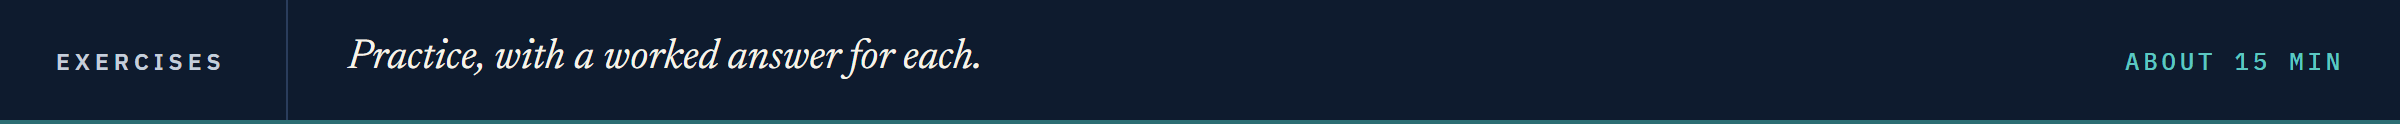

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second desk's four bonds from notebook 02, on the same coupon date.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: the bonds and `check`.

In [30]:
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'years': [4, 2, 6, 8],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
exercise_bonds

,issuer,ticker,coupon_pct,years,yield_pct
0,Ostrevale Telecom,OSTV,5.625,4,5.80
1,Tarnwick Utilities,TRNW,4.375,2,4.30
2,Osmere Chemicals,OSMC,5.000,6,5.35
3,Calderby Retail,CLDB,8.250,8,8.60


In [31]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. Hold each bond's yield, and price it today and with 1 year left. Store Calderby's price with 1 year left, unrounded, in **ex1_calderby_1y** and a list of the tickers whose price falls toward 100 in **ex1_falling**.

In [32]:
ex1_calderby_1y = ...
ex1_falling = ...
check('Exercise 1 Calderby with 1 year left', ex1_calderby_1y, 99.67134685052798)
check('Exercise 1 falling toward 100', ex1_falling, ['TRNW'])

Exercise 1 Calderby with 1 year left: not attempted yet
Exercise 1 falling toward 100: not attempted yet


### Exercise 2

Q. Move Osmere's yield 100 bp down and 100 bp up. Store the two price changes in points, unrounded, in **ex2_down_points** and **ex2_up_points**, and in **ex2_larger** the word `'down'` or `'up'`: the move with the larger change in size.

In [33]:
ex2_down_points = ...
ex2_up_points = ...
ex2_larger = ...
check('Exercise 2 yield down 100 bp', ex2_down_points, 5.176570543702951)
check('Exercise 2 yield up 100 bp', ex2_up_points, -4.873065902034114)
check('Exercise 2 larger move', ex2_larger, 'down')

Exercise 2 yield down 100 bp: not attempted yet
Exercise 2 yield up 100 bp: not attempted yet
Exercise 2 larger move: not attempted yet


### Exercise 3

Q. With `bondmath.convert_yield`, restate Calderby's semiannual yield as an annual rate and Osmere's as a quarterly rate. Store them, in percent and unrounded, in **ex3_calderby_annual** and **ex3_osmere_quarterly**.

In [34]:
ex3_calderby_annual = ...
ex3_osmere_quarterly = ...
check('Exercise 3 Calderby annual', ex3_calderby_annual, 8.784899999999984)
check('Exercise 3 Osmere quarterly', ex3_osmere_quarterly, 5.314692553822908)

Exercise 3 Calderby annual: not attempted yet
Exercise 3 Osmere quarterly: not attempted yet


### Exercise 4

Q. Add `price_change(old_price, new_price)`, returning a tuple: the change in points per 100 of face, and in percent of the old price, both negative for a fall. Write the docstring first: units, convention, and the Excel formula.
Add `test_price_change_points_and_percent`: two cases you can check by hand, and a check that every step up Quorvane's `PRICE` column (the `tvm_rows("PRICE")` rows with coupon `"5.25"`) is a fall.
Write each in its cell below and run it once, run pytest, reload the module, and store the percent change of Halvering's price from a 7.70 to an 8.70 yield, from `bondmath.price_change`, in **ex4_percent**.

In [35]:
%%writefile -a bondmath.py


# Exercise 4: write price_change(old_price, new_price) below this line

Appending to bondmath.py


In [36]:
%%writefile -a test_bondmath.py


# Exercise 4: write test_price_change_points_and_percent() below this line

Appending to test_bondmath.py


In [37]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........                                                                 [100%]
8 passed in 0.50s



In [38]:
# reload the module, then call your function
ex4_percent = ...
check('Exercise 4 percent change', ex4_percent, -6.621129485219808)

Exercise 4 percent change: not attempted yet


### Exercise 5: AI check

You gave an AI assistant `convert_yield`'s docstring: the docstring is the prompt.
The function below came back; it runs, returns a number, and holds one convention error.

In [39]:
# written for this course in the style of an AI assistant's answer. It runs, and it holds one bug.
def assistant_convert_yield(yield_pct, from_frequency, to_frequency):
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    """
    growth_one_year = (1 + yield_pct / from_frequency) ** from_frequency
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    return period_rate * to_frequency

Q. Test it against every `EFFECT` and `NOMINAL` row before you trust it.

In [40]:
for case, rate, frequency, excel in zip(effect_rows.index, effect_rows['rate_pct'],
                                        effect_rows['frequency'], effect_rows['excel_value']):
    result = assistant_convert_yield(rate, frequency, 1)
    # Excel returns a decimal, the docstring promises a percent
    assert abs(result - excel * 100) < 1e-9, f'{case}: {result:.6f} against {excel * 100:.6f}'
for case, rate, frequency, excel in zip(nominal_rows.index, nominal_rows['rate_pct'],
                                        nominal_rows['frequency'], nominal_rows['excel_value']):
    result = assistant_convert_yield(rate, 1, frequency)
    assert abs(result - excel * 100) < 1e-9, f'{case}: {result:.6f} against {excel * 100:.6f}'
print(f'All {len(effect_rows) + len(nominal_rows)} EFFECT and NOMINAL rows match Excel')

AssertionError: tvm_effect_01: 11.250000 against 5.062500

Q. Find the convention the code broke, fix it in its cell, and run both cells again until every row matches. Store `assistant_convert_yield(5.4, 2, 1)` in **ex5_quorvane** and the rows checked in **ex5_rows**.

In [41]:
ex5_quorvane = ...
ex5_rows = ...
check('Exercise 5 Quorvane annual', ex5_quorvane, 5.472899999999981)
check('Exercise 5 rows checked', ex5_rows, 22)

Exercise 5 Quorvane annual: not attempted yet
Exercise 5 rows checked: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Why each sits there</td><td align="left">coupon against yield; Pellwick's premium is its extra coupon, 0.4159</td></tr>
<tr><td align="left">How prices move</td><td align="left">along a curve: Quorvane +4.43 for 100 bp down, -4.21 for 100 bp up</td></tr>
<tr><td align="left">Which moves most</td><td align="left">Halvering, -6.62 percent for 100 bp up: the longest</td></tr>
<tr><td align="left">If yields never move</td><td align="left">each walks to 100 and earns its yield</td></tr>
<tr><td align="left">5.45 annual or 5.40 semiannual</td><td align="left">Quorvane: 5.4729 annual</td></tr>
<tr><td align="left">In the module</td><td align="left"><code>convert_yield</code>, <code>8 passed</code> on 22 Excel rows</td></tr>
<tr><td align="left">Saved and taken home</td><td align="left">a commit that says why, in <code>my_bondmath</code></td></tr>
</table>
<br clear="left">

Be proud: you read a quote the way a desk does, from the coupon, the yield, the term, and the frequency.
Next, Yield From Price: the arrow turns, from a quoted price back to its yield, where there is no formula to write.

[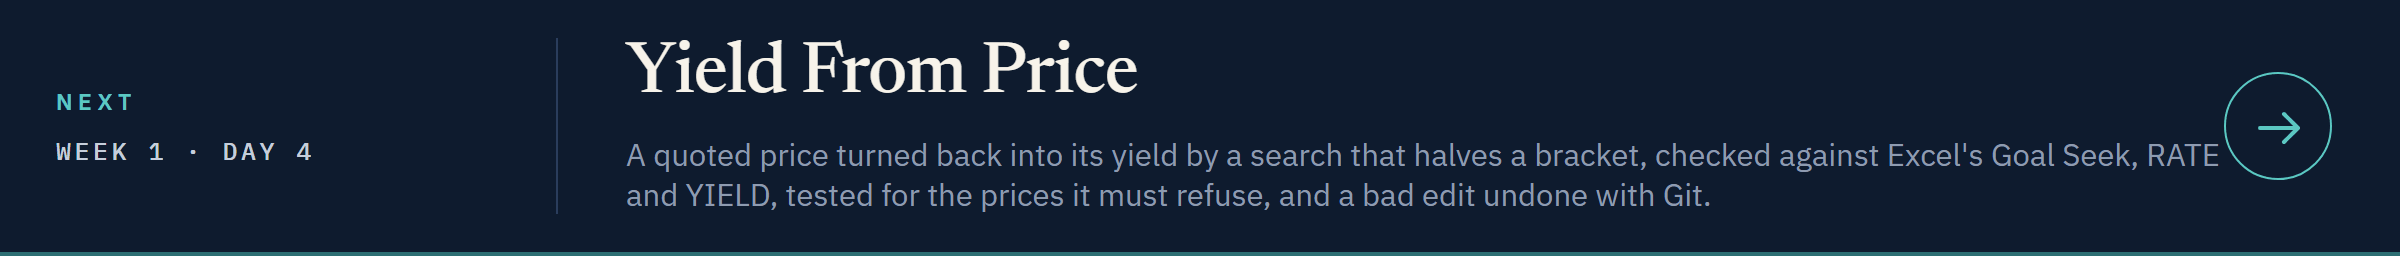](../day4/04_yield_from_price.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day4/04_yield_from_price.ipynb)